# Variational Autoencoder on MNIST
Executed PyTorch comparison of reconstruction and generation using a fully connected VAE.
See README.md for results, data and evaluation conventions, and PERSONAL_CONTRIBUTION.md for contribution and assistance details.

## 1. Set up the experiment
Use a standard Colab Python runtime. A GPU is optional. Fix the configuration before training; do not change it after inspecting test results.

In [1]:
from pathlib import Path
import json, csv, random, platform, hashlib, zipfile, time
from importlib.metadata import version
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import MNIST
from torchvision import transforms

ROOT = Path('vae_mnist_project')
DATA = ROOT / 'data'
RESULTS = ROOT / 'results'
RESULTS.mkdir(parents=True, exist_ok=True)
CONFIG = dict(seed=42, hidden_dim=200, latent_dim=25, batch_size=100,
              learning_rate=0.001, epochs=15, validation_size=6000,
              beta=1.0, evaluation_seed=2026, generation_seed=2027)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed(CONFIG['seed'])
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
environment = dict(python=platform.python_version(),
    packages={p:version(p) for p in ['torch','torchvision','numpy','matplotlib']},
    device=str(DEVICE), cuda_runtime=torch.version.cuda,
    reproducibility='Fixed seeds; bitwise equality across platforms or versions is not guaranteed.')
(RESULTS/'config.json').write_text(json.dumps(CONFIG,indent=2))
(RESULTS/'environment.json').write_text(json.dumps(environment,indent=2))
print(json.dumps(environment,indent=2))
print('CHECKPOINT 1: environment and fixed configuration recorded')

{
  "python": "3.13.18",
  "packages": {
    "torch": "2.14.1+cpu",
    "torchvision": "0.29.1+cpu",
    "numpy": "2.4.6",
    "matplotlib": "3.10.0"
  },
  "device": "cpu",
  "cuda_runtime": null,
  "reproducibility": "Fixed seeds; bitwise equality across platforms or versions is not guaranteed."
}
CHECKPOINT 1: environment and fixed configuration recorded


## 2. Load MNIST and reserve validation and test data
Use 54,000 training images and 6,000 validation images from the official training set. Reserve all 10,000 official test images. Digit labels are not used in the training loss.

100%|██████████| 9.91M/9.91M [00:00<00:00, 36.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.12MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.82MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.77MB/s]


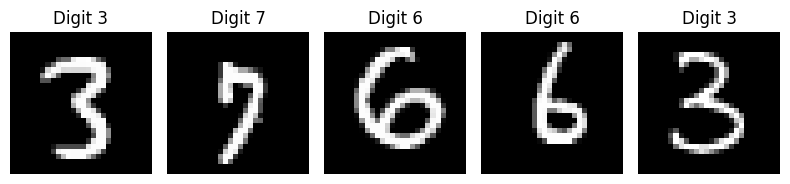

Training: 54000 Validation: 6000 Test: 10000
CHECKPOINT 2: official partitions and training-only split recorded


In [2]:
full_train = MNIST(str(DATA), train=True, download=True, transform=transforms.ToTensor())
test_data = MNIST(str(DATA), train=False, download=True, transform=transforms.ToTensor())
assert len(full_train)==60000 and len(test_data)==10000
split_gen = torch.Generator().manual_seed(CONFIG['seed'])
order = torch.randperm(len(full_train),generator=split_gen).tolist()
val_ids = order[:CONFIG['validation_size']]
train_ids = order[CONFIG['validation_size']:]
assert set(train_ids).isdisjoint(val_ids)
train_data = Subset(full_train,train_ids)
val_data = Subset(full_train,val_ids)
train_loader = DataLoader(train_data,batch_size=CONFIG['batch_size'],shuffle=True,
    num_workers=0,generator=torch.Generator().manual_seed(CONFIG['seed']))
val_loader = DataLoader(val_data,batch_size=CONFIG['batch_size'],shuffle=False,num_workers=0)
test_loader = DataLoader(test_data,batch_size=CONFIG['batch_size'],shuffle=False,num_workers=0)
with (RESULTS/'split_assignments.csv').open('w',newline='') as f:
    writer=csv.writer(f);writer.writerow(['official_partition','image_index','partition'])
    writer.writerows(('train',i,'train') for i in train_ids)
    writer.writerows(('train',i,'validation') for i in val_ids)
    writer.writerows(('test',i,'test') for i in range(len(test_data)))
hashes={p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in (DATA/'MNIST'/'raw').glob('*.gz')}
provenance=dict(dataset='MNIST',
    source='https://yann.lecun.com/exdb/mnist/',
    loader='torchvision.datasets.MNIST',
    reference='LeCun, Cortes and Burges. The MNIST database of handwritten digits.',
    training_images=len(train_data),validation_images=len(val_data),test_images=len(test_data),
    input_shape=[1,28,28],pixel_transform='ToTensor: integer pixels scaled to [0,1]',
    archive_sha256=hashes,
    redistribution='Raw dataset is not redistributed; use the documented source and loader.')
(RESULTS/'data_provenance.json').write_text(json.dumps(provenance,indent=2))
fig,axes=plt.subplots(1,5,figsize=(8,2))
for ax,index in zip(axes,train_ids[:5]):
    image,label=full_train[index];ax.imshow(image.squeeze(),cmap='gray',vmin=0,vmax=1)
    ax.set_title(f'Digit {label}');ax.axis('off')
fig.tight_layout();fig.savefig(RESULTS/'training_examples.png',dpi=160);plt.show()
print('Training:',len(train_data),'Validation:',len(val_data),'Test:',len(test_data))
print('CHECKPOINT 2: official partitions and training-only split recorded')

## 3. Define the VAE and check its shapes
The encoder predicts a mean and log variance. The reparameterization step samples a latent vector; the decoder reconstructs the input. Check dimensions and finite gradients before training.

In [3]:
class VAE(nn.Module):
    def __init__(self,hidden_dim=200,latent_dim=25):
        super().__init__()
        self.encoder=nn.Sequential(nn.Linear(784,hidden_dim),nn.ReLU())
        self.fc_mu=nn.Linear(hidden_dim,latent_dim)
        self.fc_logvar=nn.Linear(hidden_dim,latent_dim)
        self.decoder=nn.Sequential(nn.Linear(latent_dim,hidden_dim),nn.ReLU(),
                                   nn.Linear(hidden_dim,784),nn.Sigmoid())
    def encode(self,x):
        h=self.encoder(x.flatten(start_dim=1))
        return self.fc_mu(h),self.fc_logvar(h)
    def decode(self,z): return self.decoder(z)
    def forward(self,x,generator=None):
        mu,logvar=self.encode(x)
        noise=torch.randn(mu.shape,device=mu.device,dtype=mu.dtype,generator=generator)
        z=mu+noise*torch.exp(0.5*logvar)
        return self.decode(z),mu,logvar

def loss_components(recon,x,mu,logvar):
    bce=F.binary_cross_entropy(recon,x.flatten(start_dim=1),reduction='sum')
    kl=-0.5*torch.sum(1+logvar-mu.pow(2)-logvar.exp())
    total=bce+CONFIG['beta']*kl
    return total,bce,kl

probe=VAE(CONFIG['hidden_dim'],CONFIG['latent_dim']).to(DEVICE)
probe_x=next(iter(val_loader))[0][:4].to(DEVICE)
probe_recon,probe_mu,probe_logvar=probe(probe_x)
assert probe_recon.shape==(4,784)
assert probe_mu.shape==(4,CONFIG['latent_dim'])
assert bool(((probe_recon>=0)&(probe_recon<=1)).all())
probe_loss,_,_=loss_components(probe_recon,probe_x,probe_mu,probe_logvar)
assert bool(torch.isfinite(probe_loss))
probe_loss.backward()
assert all(bool(torch.isfinite(p.grad).all()) for p in probe.parameters() if p.grad is not None)
del probe
print('Input:',tuple(probe_x.shape),'Reconstruction:',tuple(probe_recon.shape))
print('CHECKPOINT 3: shape, range, finite-loss and gradient checks passed')

Input: (4, 1, 28, 28) Reconstruction: (4, 784)
CHECKPOINT 3: shape, range, finite-loss and gradient checks passed


## 4. Train and select the checkpoint using validation data
Train for the fixed 15 epochs. Select the lowest validation total loss, not a visually preferred test output. Validation sampling uses its own seeded generator so it does not consume the training random stream.

In [4]:
set_seed(CONFIG['seed'])
model=VAE(CONFIG['hidden_dim'],CONFIG['latent_dim']).to(DEVICE)
optimizer=torch.optim.Adam(model.parameters(),lr=CONFIG['learning_rate'])

@torch.no_grad()
def evaluate(model,loader,seed):
    model.eval()
    totals=np.zeros(4,dtype=float);count=0
    generator=torch.Generator(device=DEVICE).manual_seed(seed)
    for x,_ in loader:
        x=x.to(DEVICE)
        recon,mu,logvar=model(x,generator=generator)
        loss,bce,kl=loss_components(recon,x,mu,logvar)
        mean_reconstruction=model.decode(mu)
        squared_error=F.mse_loss(mean_reconstruction,x.flatten(start_dim=1),reduction='sum')
        totals+=np.array([loss.item(),bce.item(),kl.item(),squared_error.item()])
        count+=x.size(0)
    return dict(total_per_image=totals[0]/count,bce_per_image=totals[1]/count,
        kl_per_image=totals[2]/count,mean_reconstruction_mse_per_pixel=totals[3]/(count*784))

history=[];best_val=float('inf');best_epoch=None;start=time.time()
for epoch in range(1,CONFIG['epochs']+1):
    model.train();sums=np.zeros(3,dtype=float);seen=0
    for x,_ in train_loader:
        x=x.to(DEVICE);optimizer.zero_grad(set_to_none=True)
        recon,mu,logvar=model(x)
        total,bce,kl=loss_components(recon,x,mu,logvar)
        assert bool(torch.isfinite(total)), 'Non-finite training loss; stop and inspect.'
        (total/x.size(0)).backward();optimizer.step()
        sums+=np.array([total.item(),bce.item(),kl.item()]);seen+=x.size(0)
    val=evaluate(model,val_loader,CONFIG['evaluation_seed'])
    assert np.isfinite(list(val.values())).all()
    row=dict(epoch=epoch,train_total_per_image=sums[0]/seen,
        train_bce_per_image=sums[1]/seen,train_kl_per_image=sums[2]/seen,
        **{'validation_'+k:v for k,v in val.items()})
    history.append(row)
    if val['total_per_image']<best_val:
        best_val=val['total_per_image'];best_epoch=epoch
        torch.save({k:v.detach().cpu().clone() for k,v in model.state_dict().items()},
                   RESULTS/'best_model_state.pt')
    with (RESULTS/'training_history.csv').open('w',newline='') as f:
        writer=csv.DictWriter(f,fieldnames=list(history[0]));writer.writeheader();writer.writerows(history)
    print(f"Epoch {epoch:02d}: train={sums[0]/seen:.3f}, validation={val['total_per_image']:.3f}")
selection=dict(best_epoch=best_epoch,best_validation_total_per_image=best_val,
    criterion='Minimum validation BCE + beta * KL per image',
    beta=CONFIG['beta'],epochs_completed=len(history),training_seconds=time.time()-start,
    test_used_for_selection=False)
(RESULTS/'checkpoint_selection.json').write_text(json.dumps(selection,indent=2))
print(json.dumps(selection,indent=2))
print('CHECKPOINT 4: checkpoint selected using validation only')

Epoch 01: train=177.671, validation=140.069
Epoch 02: train=130.510, validation=124.880
Epoch 03: train=120.763, validation=118.416
Epoch 04: train=116.267, validation=115.392
Epoch 05: train=113.725, validation=114.034
Epoch 06: train=112.174, validation=112.494
Epoch 07: train=111.079, validation=111.312
Epoch 08: train=110.293, validation=110.739
Epoch 09: train=109.565, validation=110.117
Epoch 10: train=109.123, validation=109.974
Epoch 11: train=108.682, validation=109.456
Epoch 12: train=108.302, validation=109.007
Epoch 13: train=107.960, validation=108.737
Epoch 14: train=107.738, validation=108.563
Epoch 15: train=107.478, validation=108.260
{
  "best_epoch": 15,
  "best_validation_total_per_image": 108.25961572265625,
  "criterion": "Minimum validation BCE + beta * KL per image",
  "beta": 1.0,
  "epochs_completed": 15,
  "training_seconds": 210.54931592941284,
  "test_used_for_selection": false
}
CHECKPOINT 4: checkpoint selected using validation only


## 5. Plot and inspect the training curves
Compare per-image training and validation objectives, with BCE and KL shown separately. Their units are objective values, not percentages or classification accuracy.

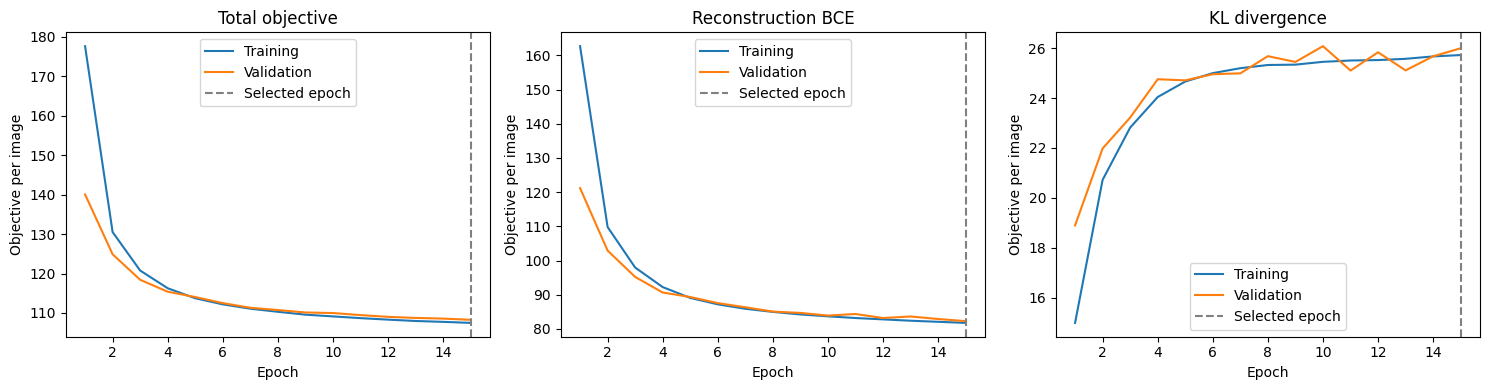

CHECKPOINT 5: learning curves saved


In [5]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,part,title in zip(axes,['total','bce','kl'],['Total objective','Reconstruction BCE','KL divergence']):
    ax.plot([r['epoch'] for r in history],[r['train_'+part+'_per_image'] for r in history],label='Training')
    ax.plot([r['epoch'] for r in history],[r['validation_'+part+'_per_image'] for r in history],label='Validation')
    ax.axvline(best_epoch,color='gray',linestyle='--',label='Selected epoch')
    ax.set_xlabel('Epoch');ax.set_ylabel('Objective per image');ax.set_title(title);ax.legend()
fig.tight_layout();fig.savefig(RESULTS/'learning_curves.png',dpi=160);plt.show()
print('CHECKPOINT 5: learning curves saved')

## 6. Evaluate the selected checkpoint on official test images
Load the validation-selected weights. Report total objective, BCE and KL per image using one seeded latent sample per image. Separately report deterministic mean-latent reconstruction MSE per pixel.

In [6]:
model.load_state_dict(torch.load(RESULTS/'best_model_state.pt',map_location=DEVICE,weights_only=True))
test_metrics=evaluate(model,test_loader,seed=CONFIG['evaluation_seed']+1)
test_metrics.update(test_images=len(test_data),selected_epoch=best_epoch,
    beta=CONFIG['beta'],evaluation='One fixed-seed latent sample per image for BCE/KL; posterior-mean decode for MSE')
(RESULTS/'test_metrics.json').write_text(json.dumps(test_metrics,indent=2))
print(json.dumps(test_metrics,indent=2))
print('CHECKPOINT 6: held-out metrics recorded; no test-based tuning')

{
  "total_per_image": 106.80011767578125,
  "bce_per_image": 80.77366328125,
  "kl_per_image": 26.02645393066406,
  "mean_reconstruction_mse_per_pixel": 0.00964393842658218,
  "test_images": 10000,
  "selected_epoch": 15,
  "beta": 1.0,
  "evaluation": "One fixed-seed latent sample per image for BCE/KL; posterior-mean decode for MSE"
}
CHECKPOINT 6: held-out metrics recorded; no test-based tuning


## 7. Visualize reconstructions and generated samples
Use the first ten official test images for reconstruction examples and a fixed seed for generated samples. Do not cherry-pick visually successful images. No digit-classification accuracy is reported.

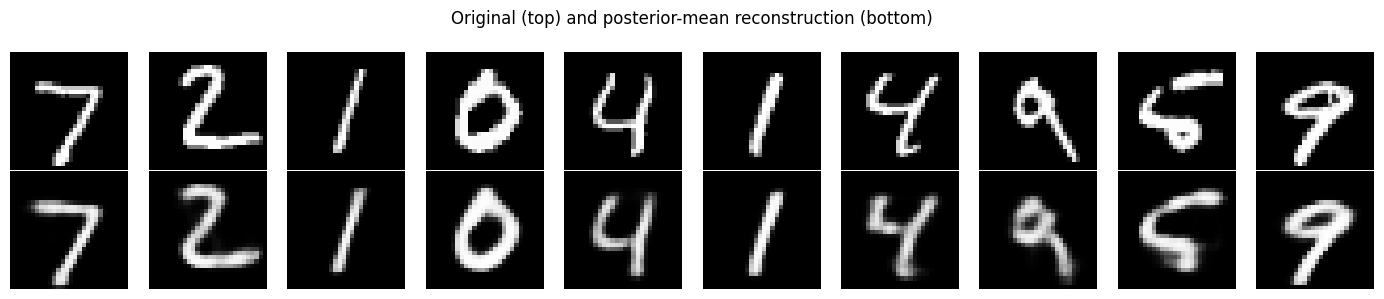

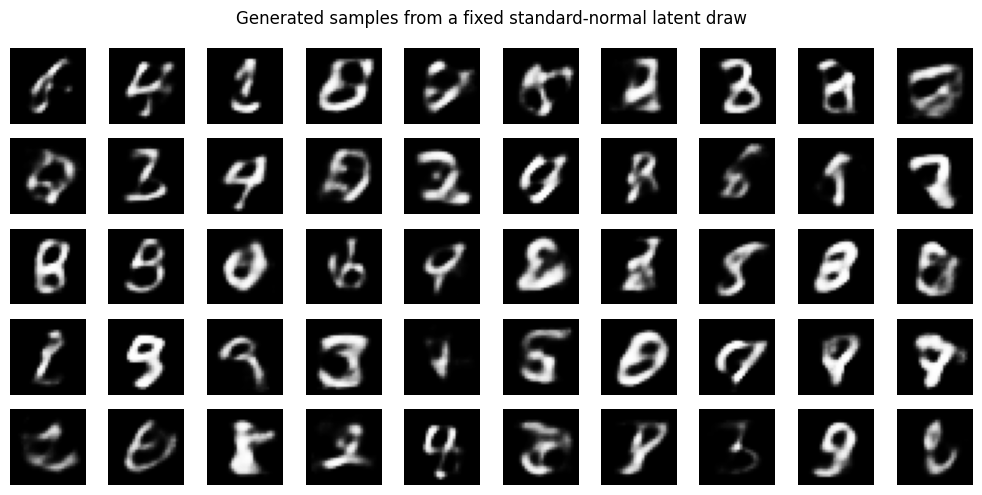

CHECKPOINT 7: fixed-example figures and model reload check complete


In [7]:
model.eval()
fixed_x=torch.stack([test_data[i][0] for i in range(10)]).to(DEVICE)
with torch.no_grad():
    fixed_mu,_=model.encode(fixed_x)
    reconstructed=model.decode(fixed_mu).reshape(-1,1,28,28).cpu()
    gen=torch.Generator(device=DEVICE).manual_seed(CONFIG['generation_seed'])
    latent=torch.randn((50,CONFIG['latent_dim']),generator=gen,device=DEVICE)
    generated=model.decode(latent).reshape(-1,1,28,28).cpu()
fig,axes=plt.subplots(2,10,figsize=(14,3))
for i in range(10):
    axes[0,i].imshow(fixed_x[i,0].cpu(),cmap='gray',vmin=0,vmax=1)
    axes[1,i].imshow(reconstructed[i,0],cmap='gray',vmin=0,vmax=1)
    for row in range(2):axes[row,i].axis('off')
fig.suptitle('Original (top) and posterior-mean reconstruction (bottom)')
fig.tight_layout();fig.savefig(RESULTS/'reconstructions.png',dpi=160);plt.show()
fig,axes=plt.subplots(5,10,figsize=(10,5))
for ax,image in zip(axes.flat,generated):
    ax.imshow(image[0],cmap='gray',vmin=0,vmax=1);ax.axis('off')
fig.suptitle('Generated samples from a fixed standard-normal latent draw')
fig.tight_layout();fig.savefig(RESULTS/'generated_samples.png',dpi=160);plt.show()
reloaded=VAE(CONFIG['hidden_dim'],CONFIG['latent_dim']).to(DEVICE)
reloaded.load_state_dict(torch.load(RESULTS/'best_model_state.pt',map_location=DEVICE,weights_only=True))
reloaded.eval()
with torch.no_grad():
    reload_mu,_=reloaded.encode(fixed_x)
    reload_reconstruction=reloaded.decode(reload_mu)
    assert torch.allclose(reload_reconstruction,model.decode(fixed_mu),atol=1e-7,rtol=1e-6)
checks=dict(disjoint_train_validation_indices=True,official_test_set_reserved=True,
    smoke_shape_and_gradient_checks_passed=True,reload_mean_reconstruction_match=True,
    selected_using_validation_only=True,training_images=len(train_data),
    validation_images=len(val_data),test_images=len(test_data))
(RESULTS/'checks.json').write_text(json.dumps(checks,indent=2))
print('CHECKPOINT 7: fixed-example figures and model reload check complete')

## 8. Export results and documentation

Record the configuration, objective conventions and figures, then export the result files. See the reviewed repository README for the final report.

In [8]:
readme=f'''# Variational Autoencoder on MNIST

An educational PyTorch VAE portfolio refresh based on earlier ML for Bioinformatics coursework, using an AI-assisted starter workflow.

## Objective
Reconstruct handwritten-digit images and generate samples from a standard-normal latent prior. This is not a classifier or biomedical model.

## Data and design
MNIST: https://yann.lecun.com/exdb/mnist/
Reference: LeCun, Cortes and Burges. The MNIST database of handwritten digits.
Loaded with torchvision.datasets.MNIST. Raw images are not redistributed.
Training: {len(train_data)} images; validation: {len(val_data)}; official test: {len(test_data)}.
Architecture: 784 -> {CONFIG['hidden_dim']} -> mean/log-variance ({CONFIG['latent_dim']} dimensions), then {CONFIG['latent_dim']} -> {CONFIG['hidden_dim']} -> 784 sigmoid pixels.
Training labels are not used in the loss. The fixed epoch budget is {CONFIG['epochs']}; the selected epoch is {best_epoch}, chosen by validation total objective.

## Evaluation convention
Total objective = BCE + beta * KL, with beta={CONFIG['beta']}. BCE is summed over 784 normalized gray-valued pixels; KL is summed over latent dimensions. Reported terms are divided by image count, not expressed as accuracy.
Validation/test BCE and KL use one fixed-seed latent sample per image. Mean-latent reconstruction MSE is reported separately per pixel. These estimates are not calibrated likelihoods, image-recognition accuracy or comprehensive generative-quality scores.

## Results from this run
```json
{json.dumps(test_metrics,indent=2)}
```
![Learning curves](results/learning_curves.png)
![Reconstructions](results/reconstructions.png)
![Generated samples](results/generated_samples.png)

## Reproducibility and limitations
Use the executed notebook and recorded configuration, split indices and environment. A CPU works; runtime depends on hardware. Fixed seeds do not guarantee bitwise reproducibility across versions or devices.
This is a small fully connected VAE on handwritten digits, not a clinical or genomics application. A single run, one-sample objective estimates and fixed visual grids do not establish broad sample quality or superiority over other models. No FID score or classifier accuracy was computed.

## Sources and assistance
The core architecture follows Sara's earlier course exercise; this refreshed split, evaluation and reporting workflow was prepared with AI assistance. Personal execution, modifications and interpretation must be documented from the completed run, without claiming sole authorship of supplied code.
Related official references: https://github.com/pytorch/examples/tree/main/vae and https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html
'''
(ROOT/'README.md').write_text(readme,encoding='utf-8')
(ROOT/'.gitignore').write_text('data/\n__pycache__/\n.ipynb_checkpoints/\n*.zip\n')
(ROOT/'requirements_versions.txt').write_text('\n'.join(f'{k}=={v}' for k,v in environment['packages'].items())+'\n')
contribution=ROOT/'PERSONAL_CONTRIBUTION.md'
if not contribution.exists():
    contribution.write_text('# Personal contribution\n\nThis run uses an AI-assisted starter based on earlier coursework. Complete the contribution statement after reviewing the executed notebook and results; do not claim unrecorded modifications or independent design.\n',encoding='utf-8')
bundle=Path('vae_mnist_results.zip')
with zipfile.ZipFile(bundle,'w',zipfile.ZIP_DEFLATED) as z:
    for p in ROOT.rglob('*'):
        if p.is_file() and DATA not in p.parents:z.write(p,p.relative_to(ROOT))
print('Result bundle:',bundle.name)
print('Also download the executed notebook: File > Download > Download .ipynb')
try:
    from google.colab import files
    files.download(str(bundle))
except ImportError:
    print('Local execution: collect the ZIP from the working directory.')

Result bundle: vae_mnist_results.zip
Also download the executed notebook: File > Download > Download .ipynb


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>